# MAVE Score Plotting

Pilar Alvarez Jerez \
August 2026

### Three main plot outcomes
1. MAVE correlation with other variant scores
2. MAVE correlation with GP2 AAO EUR data
3. MAVE correlation with GP2 OR

General imports

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import os
import numpy as np
from adjustText import adjust_text

Note: The sheets used here were previously merged or filtered to get the necessary information. This is not part of this script. Please see $HOME/MAVE/correlation_sheets/merge_plot.py for file creation.

Code inputs can be found in $HOME/MAVE/correlation_sheets/. Outputs within $HOME/MAVE as needed.

In [ ]:
# Set working directory
import os

target_dir = os.path.expanduser("~/MAVE") 

# Change the directory
os.chdir(target_dir)

# Print it out to verify it worked!
print("Current Working Directory:", os.getcwd())

### 1A. MAVE vs Variant Score
    - Standardized colors 
    - Pathogenicity colors
    - Variant labeling

In [ ]:
# 1. Load the MASTER dataset
df = pd.read_csv("correlation_sheets/scores_with_pathogenicity_master.csv")

my_score = "variant_score"
path_col = "Combined_MDS_PDBrowser_Classification"
variant_col = "Variant"  # Using the 'Variant' column from your table

# List of variants to label
variants_to_label = [
    "R159W", "G241R", "V414L", "V433L", "D448H", "L483P", "R502C", 
    "S310G", "N409S", "W417G", "V437I", "V499L", "E365K", "R83C", 
    "T408M", "N231K", "R324H", "P358L", "V391L", "A495P"
]

# Clean the Variant column to ensure exact matches with the label list
if variant_col in df.columns:
    df[variant_col] = df[variant_col].astype(str).str.strip()

# Quick safety net for the pathogenicity column
if path_col in df.columns:
    df[path_col] = df[path_col].fillna('Unknown').astype(str).str.strip()
    df[path_col] = df[path_col].replace({'nan': 'Unknown', '': 'Unknown', 'None': 'Unknown'})
else:
    df[path_col] = 'Unknown'

print("--- Variant Classifications Found ---")
print(df[path_col].value_counts())
print("-----------------------------------")

# 2. Build the Locked Color Palette (Custom Hex Colors)
unique_labels = df[path_col].unique()
custom_palette = {}

for label in unique_labels:
    label_lower = str(label).lower()
    if 'likely pathogenic' in label_lower:
        custom_palette[label] = '#F9A825'
    elif 'pathogenic' in label_lower:
        custom_palette[label] = '#C62828'
    elif 'likely benign' in label_lower:
        custom_palette[label] = '#4FC3F7'
    elif 'benign' in label_lower:
        custom_palette[label] = '#1565C0'
    elif 'vus' in label_lower or 'uncertain' in label_lower:
        custom_palette[label] = '#7E57C2'
    elif 'unknown' in label_lower:
        custom_palette[label] = 'grey'
    else:
        custom_palette[label] = 'grey'

# Legend and plotting order: Unknown goes to the back
order_hierarchy = ['pathogenic', 'likely pathogenic', 'vus', 'uncertain', 'likely benign', 'benign', 'unknown']
legend_order = sorted(unique_labels, key=lambda x: next((i for i, sub in enumerate(order_hierarchy) if sub in str(x).lower()), 100))

# 3. Define Predictors
predictors = [
    "SIFT", "SIFT4G", "Polyphen2_HumDiv", "Polyphen2_HumVar", "REVEL", "MutPred", "CADD", 
    "BayesDel", "ClinPred", "SNPred", "AlphaMissense", "popEVE", "EVE", "AlphScore", 
    "BayesDel_noAF", "CADD_1.7", "deep_SIFT", "gnomad40_genome_AF", "gnomad40_genome_faf95"
]

output_dir = os.path.expanduser("~/Desktop/MAVE/VARIANTS_test")
os.makedirs(output_dir, exist_ok=True)

# ==========================================
# PART 1: STANDARD SCATTER PLOTS
# ==========================================
for predictor in predictors:
    if predictor not in df.columns or predictor in ["gnomad40_genome_AF", "gnomad40_genome_faf95"]:
        continue  # Skip missing cols and gnomAD (handled in Part 2)
        
    valid_data = df[[my_score, predictor, path_col, variant_col]].copy()
    valid_data[my_score] = pd.to_numeric(valid_data[my_score], errors='coerce')
    valid_data[predictor] = pd.to_numeric(valid_data[predictor], errors='coerce')
    valid_data = valid_data.dropna(subset=[my_score, predictor])
    
    if len(valid_data) < 2:
        continue
        
    # Prevent overplotting by sorting
    valid_data['sort_key'] = valid_data[path_col].apply(lambda x: legend_order.index(x) if x in legend_order else 100)
    valid_data = valid_data.sort_values(by='sort_key', ascending=False)
    
    corr, p_value = spearmanr(valid_data[my_score], valid_data[predictor])
    
    plt.figure(figsize=(10, 6)) 
    
    sns.scatterplot(
        data=valid_data, 
        x=predictor, 
        y=my_score, 
        hue=path_col,
        hue_order=legend_order, 
        palette=custom_palette, 
        alpha=0.7, 
        edgecolor='white',
        s=50
    )
    
    m, b = np.polyfit(valid_data[predictor], valid_data[my_score], 1)
    plt.plot(valid_data[predictor], m * valid_data[predictor] + b, color='black', linewidth=2, linestyle='-')
    
    # --- ADD LABELS FOR SPECIFIC VARIANTS ---
    x_range = valid_data[predictor].max() - valid_data[predictor].min()
    y_range = valid_data[my_score].max() - valid_data[my_score].min()
    x_range = x_range if x_range > 0 else 1
    y_range = y_range if y_range > 0 else 1
    
    texts = []
    for _, row in valid_data.iterrows():
        variant_name = str(row[variant_col]).strip()
        if variant_name in variants_to_label:
            t = plt.annotate(
                variant_name, 
                xy=(row[predictor], row[my_score]), 
                xytext=(row[predictor] + (x_range * 0.03), row[my_score] + (y_range * 0.03)), 
                fontsize=8, 
                color='black',
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, ec="none"),
                arrowprops=dict(arrowstyle="-", color="black", lw=0.8, alpha=0.6)
            )
            texts.append(t)
            
    if texts:
        adjust_text(
            texts,
            x=valid_data[predictor].tolist(),  
            y=valid_data[my_score].tolist(),
            expand_points=(1.2, 1.2)
        )
    
    plt.title(f"{my_score} vs {predictor}\nSpearman r = {corr:.3f}", fontsize=14)
    plt.xlabel(predictor, fontsize=12)
    plt.ylabel(my_score, fontsize=12)
    
    plt.legend(title='Pathogenic Significance', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    # Your existing PDF save
    plt.savefig(f"{output_dir}/{predictor}_scatter.pdf", format='pdf', bbox_inches='tight')
    
    # ADD THIS LINE: Save a high-resolution PNG as well
    plt.savefig(f"{output_dir}/{predictor}_scatter.png", format='png', dpi=300, bbox_inches='tight')
    
    plt.close()

# ==========================================
# PART 2: LOGARITHMIC SCATTER PLOTS (gnomAD)
# ==========================================
gnomad_cols = ["gnomad40_genome_AF", "gnomad40_genome_faf95"]

for predictor in gnomad_cols:
    if predictor not in df.columns:
        continue
        
    valid_data = df[[my_score, predictor, path_col, variant_col]].copy()
    valid_data[my_score] = pd.to_numeric(valid_data[my_score], errors='coerce')
    valid_data[predictor] = pd.to_numeric(valid_data[predictor], errors='coerce')
    valid_data = valid_data.dropna(subset=[my_score, predictor])
    
    valid_data = valid_data[valid_data[predictor] > 0]
    
    if len(valid_data) < 2:
        continue
        
    valid_data['sort_key'] = valid_data[path_col].apply(lambda x: legend_order.index(x) if x in legend_order else 100)
    valid_data = valid_data.sort_values(by='sort_key', ascending=False)
        
    corr, p_value = spearmanr(valid_data[my_score], valid_data[predictor])
    
    plt.figure(figsize=(10, 6)) 
    
    sns.scatterplot(
        data=valid_data, 
        x=predictor, 
        y=my_score, 
        hue=path_col,
        hue_order=legend_order, 
        palette=custom_palette, 
        alpha=0.7, 
        edgecolor='white',
        s=50
    )
    
    plt.xscale('log')
    
    x_log = np.log10(valid_data[predictor])
    m, b = np.polyfit(x_log, valid_data[my_score], 1)
    
    x_line = np.logspace(np.log10(valid_data[predictor].min()), np.log10(valid_data[predictor].max()), 100)
    y_line = m * np.log10(x_line) + b
    plt.plot(x_line, y_line, color='black', linewidth=2, linestyle='-')
    
    # --- ADD LABELS FOR SPECIFIC VARIANTS (Log Space Adjusted) ---
    log_x_min = np.log10(valid_data[predictor].min())
    log_x_max = np.log10(valid_data[predictor].max())
    log_x_range = log_x_max - log_x_min if log_x_max > log_x_min else 1
    
    y_range = valid_data[my_score].max() - valid_data[my_score].min()
    y_range = y_range if y_range > 0 else 1
    
    texts = []
    for _, row in valid_data.iterrows():
        variant_name = str(row[variant_col]).strip()
        if variant_name in variants_to_label:
            # Shift slightly in log10 space for text box placement
            x_shifted = 10 ** (np.log10(row[predictor]) + (log_x_range * 0.03))
            
            t = plt.annotate(
                variant_name, 
                xy=(row[predictor], row[my_score]), 
                xytext=(x_shifted, row[my_score] + (y_range * 0.03)), 
                fontsize=8, 
                color='black',
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, ec="none"),
                arrowprops=dict(arrowstyle="-", color="black", lw=0.8, alpha=0.6)
            )
            texts.append(t)
            
    if texts:
        adjust_text(
            texts,
            x=valid_data[predictor].tolist(),  
            y=valid_data[my_score].tolist(),
            expand_points=(1.2, 1.2)
        )
    
    plt.title(f"{my_score} vs {predictor} (Log Scale)\nSpearman r = {corr:.3f}", fontsize=14)
    plt.xlabel(f"{predictor} (log10)", fontsize=12)
    plt.ylabel(my_score, fontsize=12)
    
    plt.legend(title='Pathogenic Significance', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    # Your existing PDF save
    plt.savefig(f"{output_dir}/{predictor}_log_scatter.pdf", format='pdf', bbox_inches='tight')
    
    # ADD THIS LINE: Save a high-resolution PNG as well
    plt.savefig(f"{output_dir}/{predictor}_log_scatter.png", format='png', dpi=300, bbox_inches='tight')
    
    plt.close()

print(f"All labeled scatter plots generated successfully as PDFs in: {output_dir}")

Visualize one plot as example

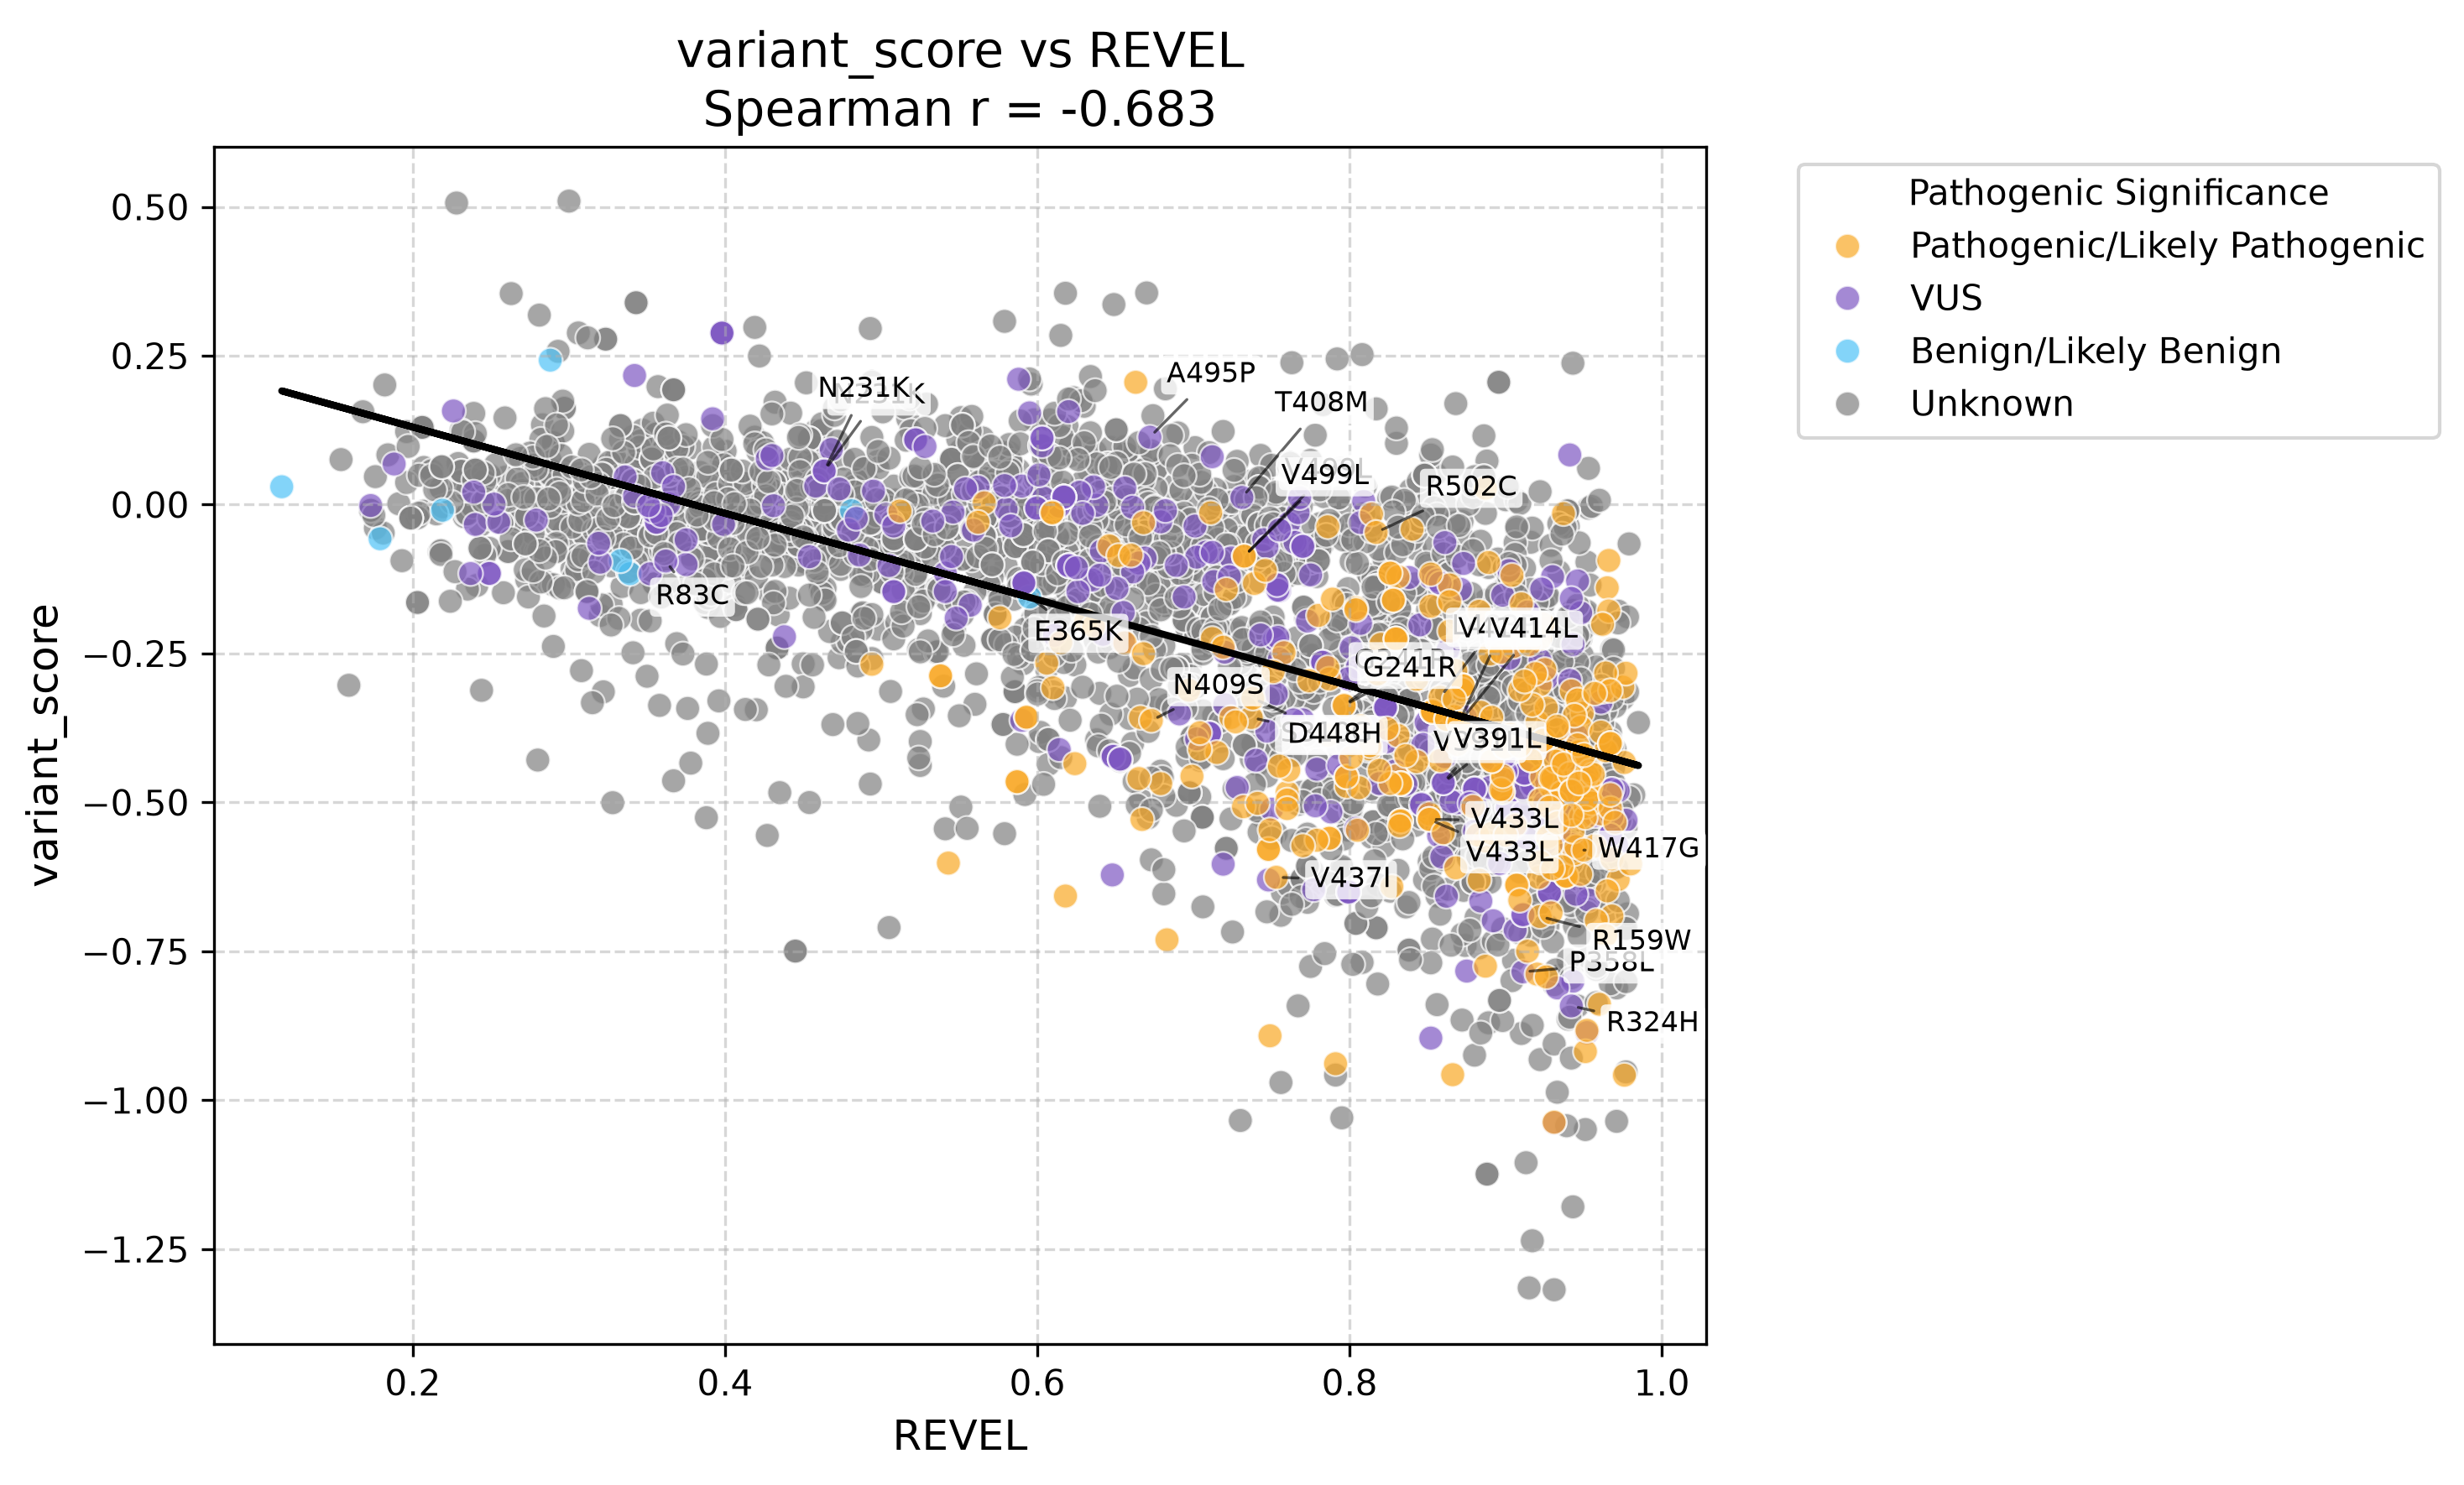

In [9]:
from IPython.display import Image, display
import os

# Define the path to the newly saved PNG
png_path = os.path.expanduser("~/Desktop/MAVE/VARIANTS_test/REVEL_scatter.png")

# Display it in the notebook
display(Image(filename=png_path))

## 1B. MAVE vs Variant Score
    - Standardized coloring
    - Pathogenicity coloring
    - NO Labeling

In [ ]:
# 1. Load the MASTER dataset
df = pd.read_csv("correlation_sheets/scores_with_pathogenicity_master.csv")

my_score = "variant_score"
path_col = "Combined_MDS_PDBrowser_Classification"
variant_col = "Variant"  

# Clean the Variant column 
if variant_col in df.columns:
    df[variant_col] = df[variant_col].astype(str).str.strip()

# Quick safety net for the pathogenicity column
if path_col in df.columns:
    df[path_col] = df[path_col].fillna('Unknown').astype(str).str.strip()
    df[path_col] = df[path_col].replace({'nan': 'Unknown', '': 'Unknown', 'None': 'Unknown'})
else:
    df[path_col] = 'Unknown'

print("--- Variant Classifications Found ---")
print(df[path_col].value_counts())
print("-----------------------------------")

# 2. Build the Locked Color Palette (Custom Hex Colors)
unique_labels = df[path_col].unique()
custom_palette = {}

for label in unique_labels:
    label_lower = str(label).lower()
    if 'likely pathogenic' in label_lower:
        custom_palette[label] = '#F9A825'
    elif 'pathogenic' in label_lower:
        custom_palette[label] = '#C62828'
    elif 'likely benign' in label_lower:
        custom_palette[label] = '#4FC3F7'
    elif 'benign' in label_lower:
        custom_palette[label] = '#1565C0'
    elif 'vus' in label_lower or 'uncertain' in label_lower:
        custom_palette[label] = '#7E57C2'
    elif 'unknown' in label_lower:
        custom_palette[label] = 'grey'
    else:
        custom_palette[label] = 'grey'

# Legend and plotting order: Unknown goes to the back
order_hierarchy = ['pathogenic', 'likely pathogenic', 'vus', 'uncertain', 'likely benign', 'benign', 'unknown']
legend_order = sorted(unique_labels, key=lambda x: next((i for i, sub in enumerate(order_hierarchy) if sub in str(x).lower()), 100))

# 3. Define Predictors
predictors = [
    "SIFT", "SIFT4G", "Polyphen2_HumDiv", "Polyphen2_HumVar", "REVEL", "MutPred", "CADD", 
    "BayesDel", "ClinPred", "SNPred", "AlphaMissense", "popEVE", "EVE", "AlphScore", 
    "BayesDel_noAF", "CADD_1.7", "deep_SIFT", "gnomad40_genome_AF", "gnomad40_genome_faf95"
]

# UPDATED DIRECTORY
output_dir = os.path.expanduser("~/Desktop/MAVE/VARIANTS_test_nolabel")
os.makedirs(output_dir, exist_ok=True)

# ==========================================
# PART 1: STANDARD SCATTER PLOTS
# ==========================================
for predictor in predictors:
    if predictor not in df.columns or predictor in ["gnomad40_genome_AF", "gnomad40_genome_faf95"]:
        continue  
        
    valid_data = df[[my_score, predictor, path_col, variant_col]].copy()
    valid_data[my_score] = pd.to_numeric(valid_data[my_score], errors='coerce')
    valid_data[predictor] = pd.to_numeric(valid_data[predictor], errors='coerce')
    valid_data = valid_data.dropna(subset=[my_score, predictor])
    
    if len(valid_data) < 2:
        continue
        
    # Prevent overplotting by sorting
    valid_data['sort_key'] = valid_data[path_col].apply(lambda x: legend_order.index(x) if x in legend_order else 100)
    valid_data = valid_data.sort_values(by='sort_key', ascending=False)
    
    corr, p_value = spearmanr(valid_data[my_score], valid_data[predictor])
    
    plt.figure(figsize=(10, 6)) 
    
    sns.scatterplot(
        data=valid_data, 
        x=predictor, 
        y=my_score, 
        hue=path_col,
        hue_order=legend_order, 
        palette=custom_palette, 
        alpha=0.7, 
        edgecolor='white',
        s=50
    )
    
    m, b = np.polyfit(valid_data[predictor], valid_data[my_score], 1)
    plt.plot(valid_data[predictor], m * valid_data[predictor] + b, color='black', linewidth=2, linestyle='-')
    
    plt.title(f"{my_score} vs {predictor}\nSpearman r = {corr:.3f}", fontsize=14)
    plt.xlabel(predictor, fontsize=12)
    plt.ylabel(my_score, fontsize=12)
    
    plt.legend(title='Pathogenic Significance', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig(f"{output_dir}/{predictor}_scatter.pdf", format='pdf', bbox_inches='tight')
    plt.savefig(f"{output_dir}/{predictor}_scatter.png", format='png', dpi=300, bbox_inches='tight')
    plt.close()

# ==========================================
# PART 2: LOGARITHMIC SCATTER PLOTS (gnomAD)
# ==========================================
gnomad_cols = ["gnomad40_genome_AF", "gnomad40_genome_faf95"]

for predictor in gnomad_cols:
    if predictor not in df.columns:
        continue
        
    valid_data = df[[my_score, predictor, path_col, variant_col]].copy()
    valid_data[my_score] = pd.to_numeric(valid_data[my_score], errors='coerce')
    valid_data[predictor] = pd.to_numeric(valid_data[predictor], errors='coerce')
    valid_data = valid_data.dropna(subset=[my_score, predictor])
    
    valid_data = valid_data[valid_data[predictor] > 0]
    
    if len(valid_data) < 2:
        continue
        
    valid_data['sort_key'] = valid_data[path_col].apply(lambda x: legend_order.index(x) if x in legend_order else 100)
    valid_data = valid_data.sort_values(by='sort_key', ascending=False)
        
    corr, p_value = spearmanr(valid_data[my_score], valid_data[predictor])
    
    plt.figure(figsize=(10, 6)) 
    
    sns.scatterplot(
        data=valid_data, 
        x=predictor, 
        y=my_score, 
        hue=path_col,
        hue_order=legend_order, 
        palette=custom_palette, 
        alpha=0.7, 
        edgecolor='white',
        s=50
    )
    
    plt.xscale('log')
    
    x_log = np.log10(valid_data[predictor])
    m, b = np.polyfit(x_log, valid_data[my_score], 1)
    
    x_line = np.logspace(np.log10(valid_data[predictor].min()), np.log10(valid_data[predictor].max()), 100)
    y_line = m * np.log10(x_line) + b
    plt.plot(x_line, y_line, color='black', linewidth=2, linestyle='-')
    
    plt.title(f"{my_score} vs {predictor} (Log Scale)\nSpearman r = {corr:.3f}", fontsize=14)
    plt.xlabel(f"{predictor} (log10)", fontsize=12)
    plt.ylabel(my_score, fontsize=12)
    
    plt.legend(title='Pathogenic Significance', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig(f"{output_dir}/{predictor}_log_scatter.pdf", format='pdf', bbox_inches='tight')
    plt.savefig(f"{output_dir}/{predictor}_log_scatter.png", format='png', dpi=300, bbox_inches='tight')
    plt.close()

print(f"All UNLABELED scatter plots generated successfully as PDFs and PNGs in: {output_dir}")

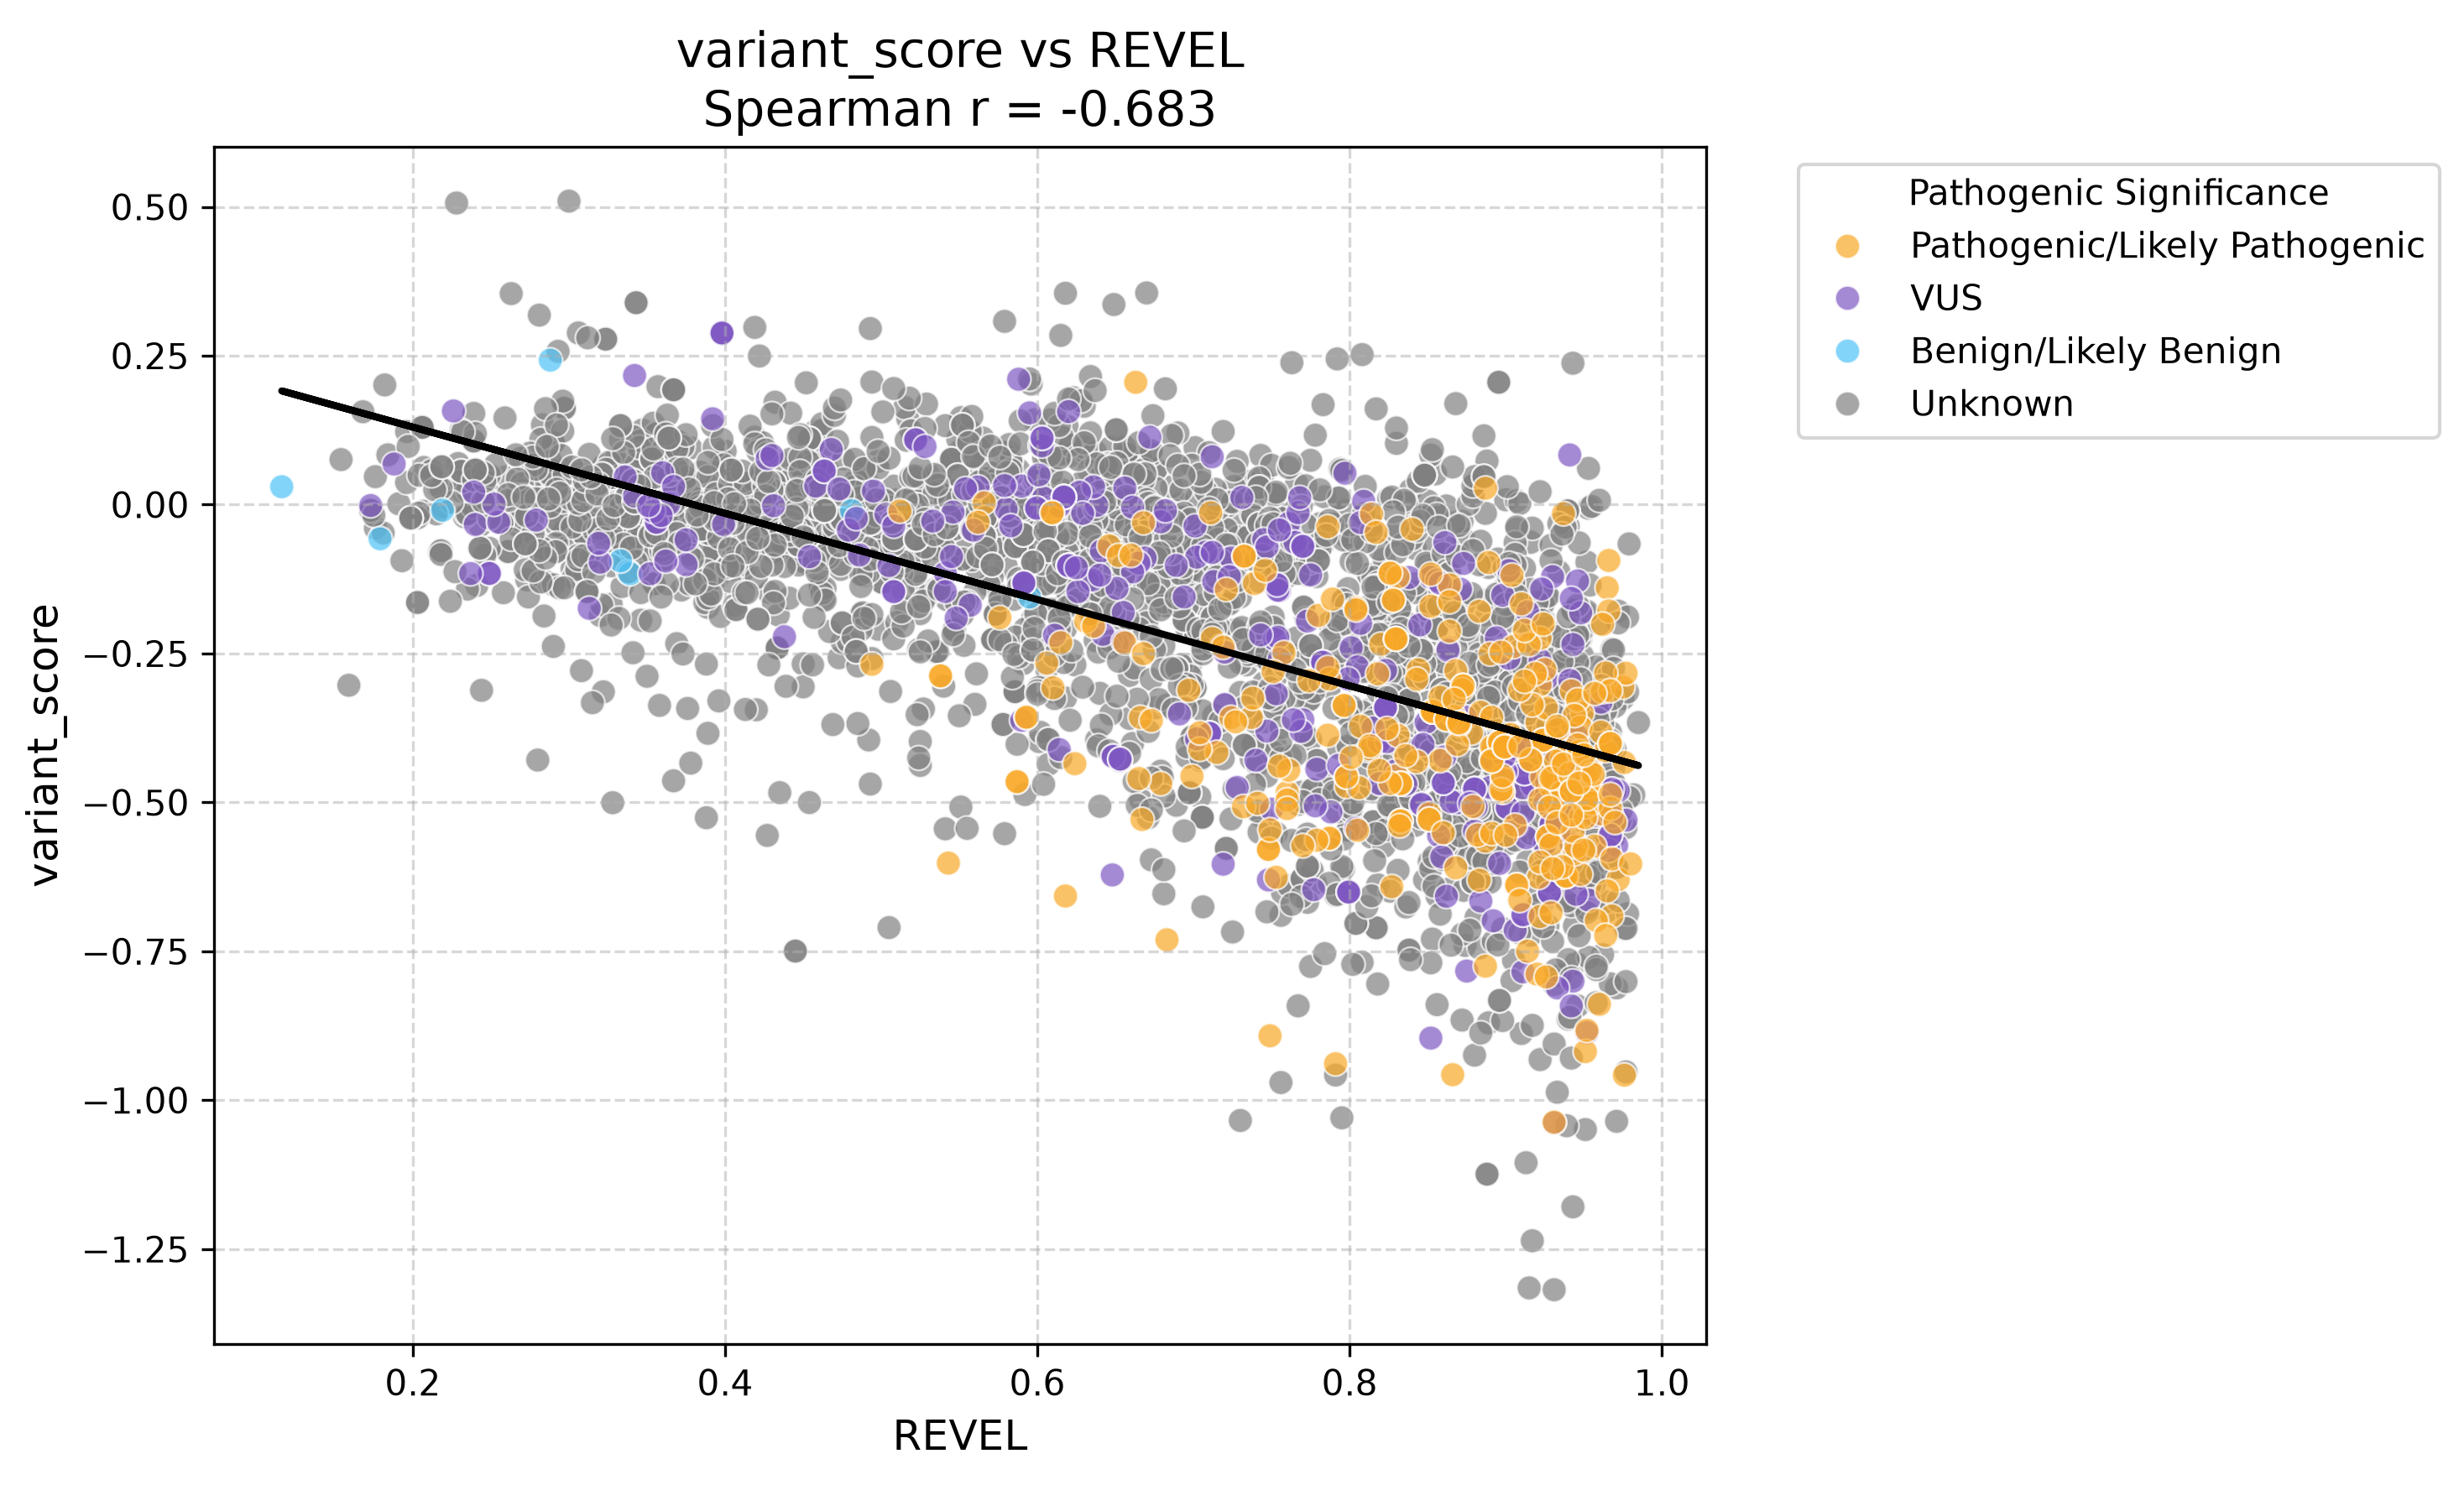

In [11]:
from IPython.display import Image, display
import os

# Define the path to the newly saved PNG
png_path = os.path.expanduser("~/Desktop/MAVE/VARIANTS_test_nolabel/REVEL_scatter.png")

# Display it in the notebook
display(Image(filename=png_path))

## 2. MAVE vs AAO
    - Standardized coloring
    - Pathogenicity coloring
    - Filtered by carriers 1,2,5,10
    - Labeled
    - All ancestries and EUR only

In [15]:

# 1. Load your dataset
df = pd.read_csv("correlation_sheets/merged_clinical_scores.csv")
path_df = pd.read_csv("correlation_sheets/pathogenicity_data.csv")

score_col = "variant_score"
target_col = "AAO"  
path_col = "Combined_MDS_PDBrowser_Classification" 

# List of variants to label
variants_to_label = [
    "R159W", "G241R", "V414L", "V433L", "D448H", "L483P", "R502C", 
    "S310G", "N409S", "W417G", "V437I", "V499L", "E365K", "R83C", 
    "T408M", "N231K", "R324H", "P358L", "V391L", "A495P"
]

# 2. Merge the pathogenicity data
aao_merge_col = "AA change.1" if "AA change.1" in df.columns else "AA change"
df = pd.merge(df, path_df[['Variant', path_col]], left_on=aao_merge_col, right_on='Variant', how='left')

# Clean up variant names
df[aao_merge_col] = df[aao_merge_col].astype(str).str.strip()

# Fill any variants that didn't have a classification with "Unknown"
df[path_col] = df[path_col].fillna('Unknown').astype(str).str.strip()
df[path_col] = df[path_col].replace({'nan': 'Unknown', '': 'Unknown', 'None': 'Unknown'})

# EXPLICIT CUSTOM COLOR MAPPING
unique_labels = df[path_col].unique()
custom_palette = {}

for label in unique_labels:
    label_lower = str(label).lower()
    
    if 'likely pathogenic' in label_lower:
        custom_palette[label] = '#F9A825'
    elif 'pathogenic' in label_lower:
        custom_palette[label] = '#C62828'
    elif 'likely benign' in label_lower:
        custom_palette[label] = '#4FC3F7'
    elif 'benign' in label_lower:
        custom_palette[label] = '#1565C0'
    elif 'vus' in label_lower or 'uncertain' in label_lower:
        custom_palette[label] = '#7E57C2'
    elif 'unknown' in label_lower:
        custom_palette[label] = 'grey'
    else:
        custom_palette[label] = 'grey'      

# 3. Clean numeric data
df[score_col] = pd.to_numeric(df[score_col], errors='coerce')
df[target_col] = pd.to_numeric(df[target_col], errors='coerce')
df = df.dropna(subset=[score_col, target_col])
df['ancestry'] = df['ancestry'].astype(str).str.strip()

# 4. Setup cohorts
cohorts = {
    "All_Ancestries": df,
    "EUR_Only": df[df['ancestry'] == 'EUR']
}

conditions = [1, 2, 5, 10]
metrics = [('mean_val', f'Mean {target_col}'), ('median_val', f'Median {target_col}')]

# 5. Loop and Plot
for cohort_name, cohort_df in cohorts.items():
    if cohort_df.empty:
        continue
        
    agg_df = cohort_df.groupby(
        ['Chr', 'Start', 'End', 'Ref', 'Alt', aao_merge_col, path_col, score_col], 
        dropna=False
    ).agg(
        carrier_count=(target_col, 'count'),
        mean_val=(target_col, 'mean'),
        median_val=(target_col, 'median')
    ).reset_index()
    
    base_out_dir = os.path.expanduser("~/Desktop/MAVE/AAO_standard")
    output_dir = os.path.join(base_out_dir, f"{target_col}_PathColored_{cohort_name}")
    os.makedirs(output_dir, exist_ok=True)
    
    for min_carriers in conditions:
        subset = agg_df[agg_df['carrier_count'] >= min_carriers]
        
        for metric_col, metric_name in metrics:
            if len(subset) < 2:
                continue
                
            corr, p_value = spearmanr(subset[score_col], subset[metric_col])
            
            plt.figure(figsize=(10, 6)) 
            
            # Scatter plot
            sns.scatterplot(
                data=subset, x=score_col, y=metric_col, hue=path_col,
                palette=custom_palette, alpha=0.7, edgecolor='white', s=50
            )
            
            # Regression line
            m, b = np.polyfit(subset[score_col], subset[metric_col], 1)
            plt.plot(subset[score_col], m * subset[score_col] + b, color='black', linewidth=2, linestyle='-')
            
            # --- CHANGED: Force Matplotlib to always draw a line by adding an initial offset ---
            x_range = subset[score_col].max() - subset[score_col].min()
            y_range = subset[metric_col].max() - subset[metric_col].min()
            
            # Fallback just in case all dots have the exact same value
            x_range = x_range if x_range > 0 else 1
            y_range = y_range if y_range > 0 else 1
            
            texts = []
            for _, row in subset.iterrows():
                variant_name = row[aao_merge_col]
                if variant_name in variants_to_label:
                    # We use plt.annotate which forces a guaranteed line from xytext to xy
                    t = plt.annotate(
                        variant_name, 
                        xy=(row[score_col], row[metric_col]), # The dot
                        # Push the text 3% up and right by default
                        xytext=(row[score_col] + (x_range * 0.03), row[metric_col] + (y_range * 0.03)), 
                        fontsize=8, 
                        color='black',
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, ec="none"),
                        arrowprops=dict(arrowstyle="-", color="black", lw=0.8, alpha=0.6)
                    )
                    texts.append(t)
            
            # adjustText will now ONLY resolve overlapping boxes. 
            # We don't pass arrowprops here because plt.annotate is already rendering them perfectly.
            if texts:
                adjust_text(
                    texts,
                    x=subset[score_col].tolist(),  
                    y=subset[metric_col].tolist(),
                    expand_points=(1.2, 1.2)
                )
            
            carrier_label = "All Variants" if min_carriers == 1 else f"\u2265 {min_carriers} Carriers"
            title_prefix = "All Ancestries" if cohort_name == "All_Ancestries" else "EUR Cohort"
            
            plt.title(f"{title_prefix}: {metric_name} vs {score_col}\n({carrier_label}) | Spearman r = {corr:.3f}", fontsize=14)
            plt.xlabel(score_col, fontsize=12)
            plt.ylabel(f"{metric_name} (Years)", fontsize=12)
            
            plt.legend(title='Pathogenic Significance', bbox_to_anchor=(1.05, 1), loc='upper left')
            plt.grid(True, linestyle='--', alpha=0.5)
            
            plt.tight_layout()
            #PNG
            file_name = f"{cohort_name}_{metric_col}_vs_score_min_{min_carriers}.png"
            plt.savefig(os.path.join(output_dir, file_name), dpi=300, bbox_inches='tight')

            # 2. ADD THIS: Save the PDF 
            pdf_name = f"{cohort_name}_{metric_col}_vs_score_min_{min_carriers}.pdf"
            plt.savefig(os.path.join(output_dir, pdf_name), format='pdf', bbox_inches='tight')
            
            plt.close()
            
    print(f"Generated {cohort_name} {target_col} plots in '{output_dir}'")

Generated All_Ancestries AAO plots in '/Users/pilaralvarezjerez/Desktop/MAVE/AAO_standard/AAO_PathColored_All_Ancestries'
Generated EUR_Only AAO plots in '/Users/pilaralvarezjerez/Desktop/MAVE/AAO_standard/AAO_PathColored_EUR_Only'


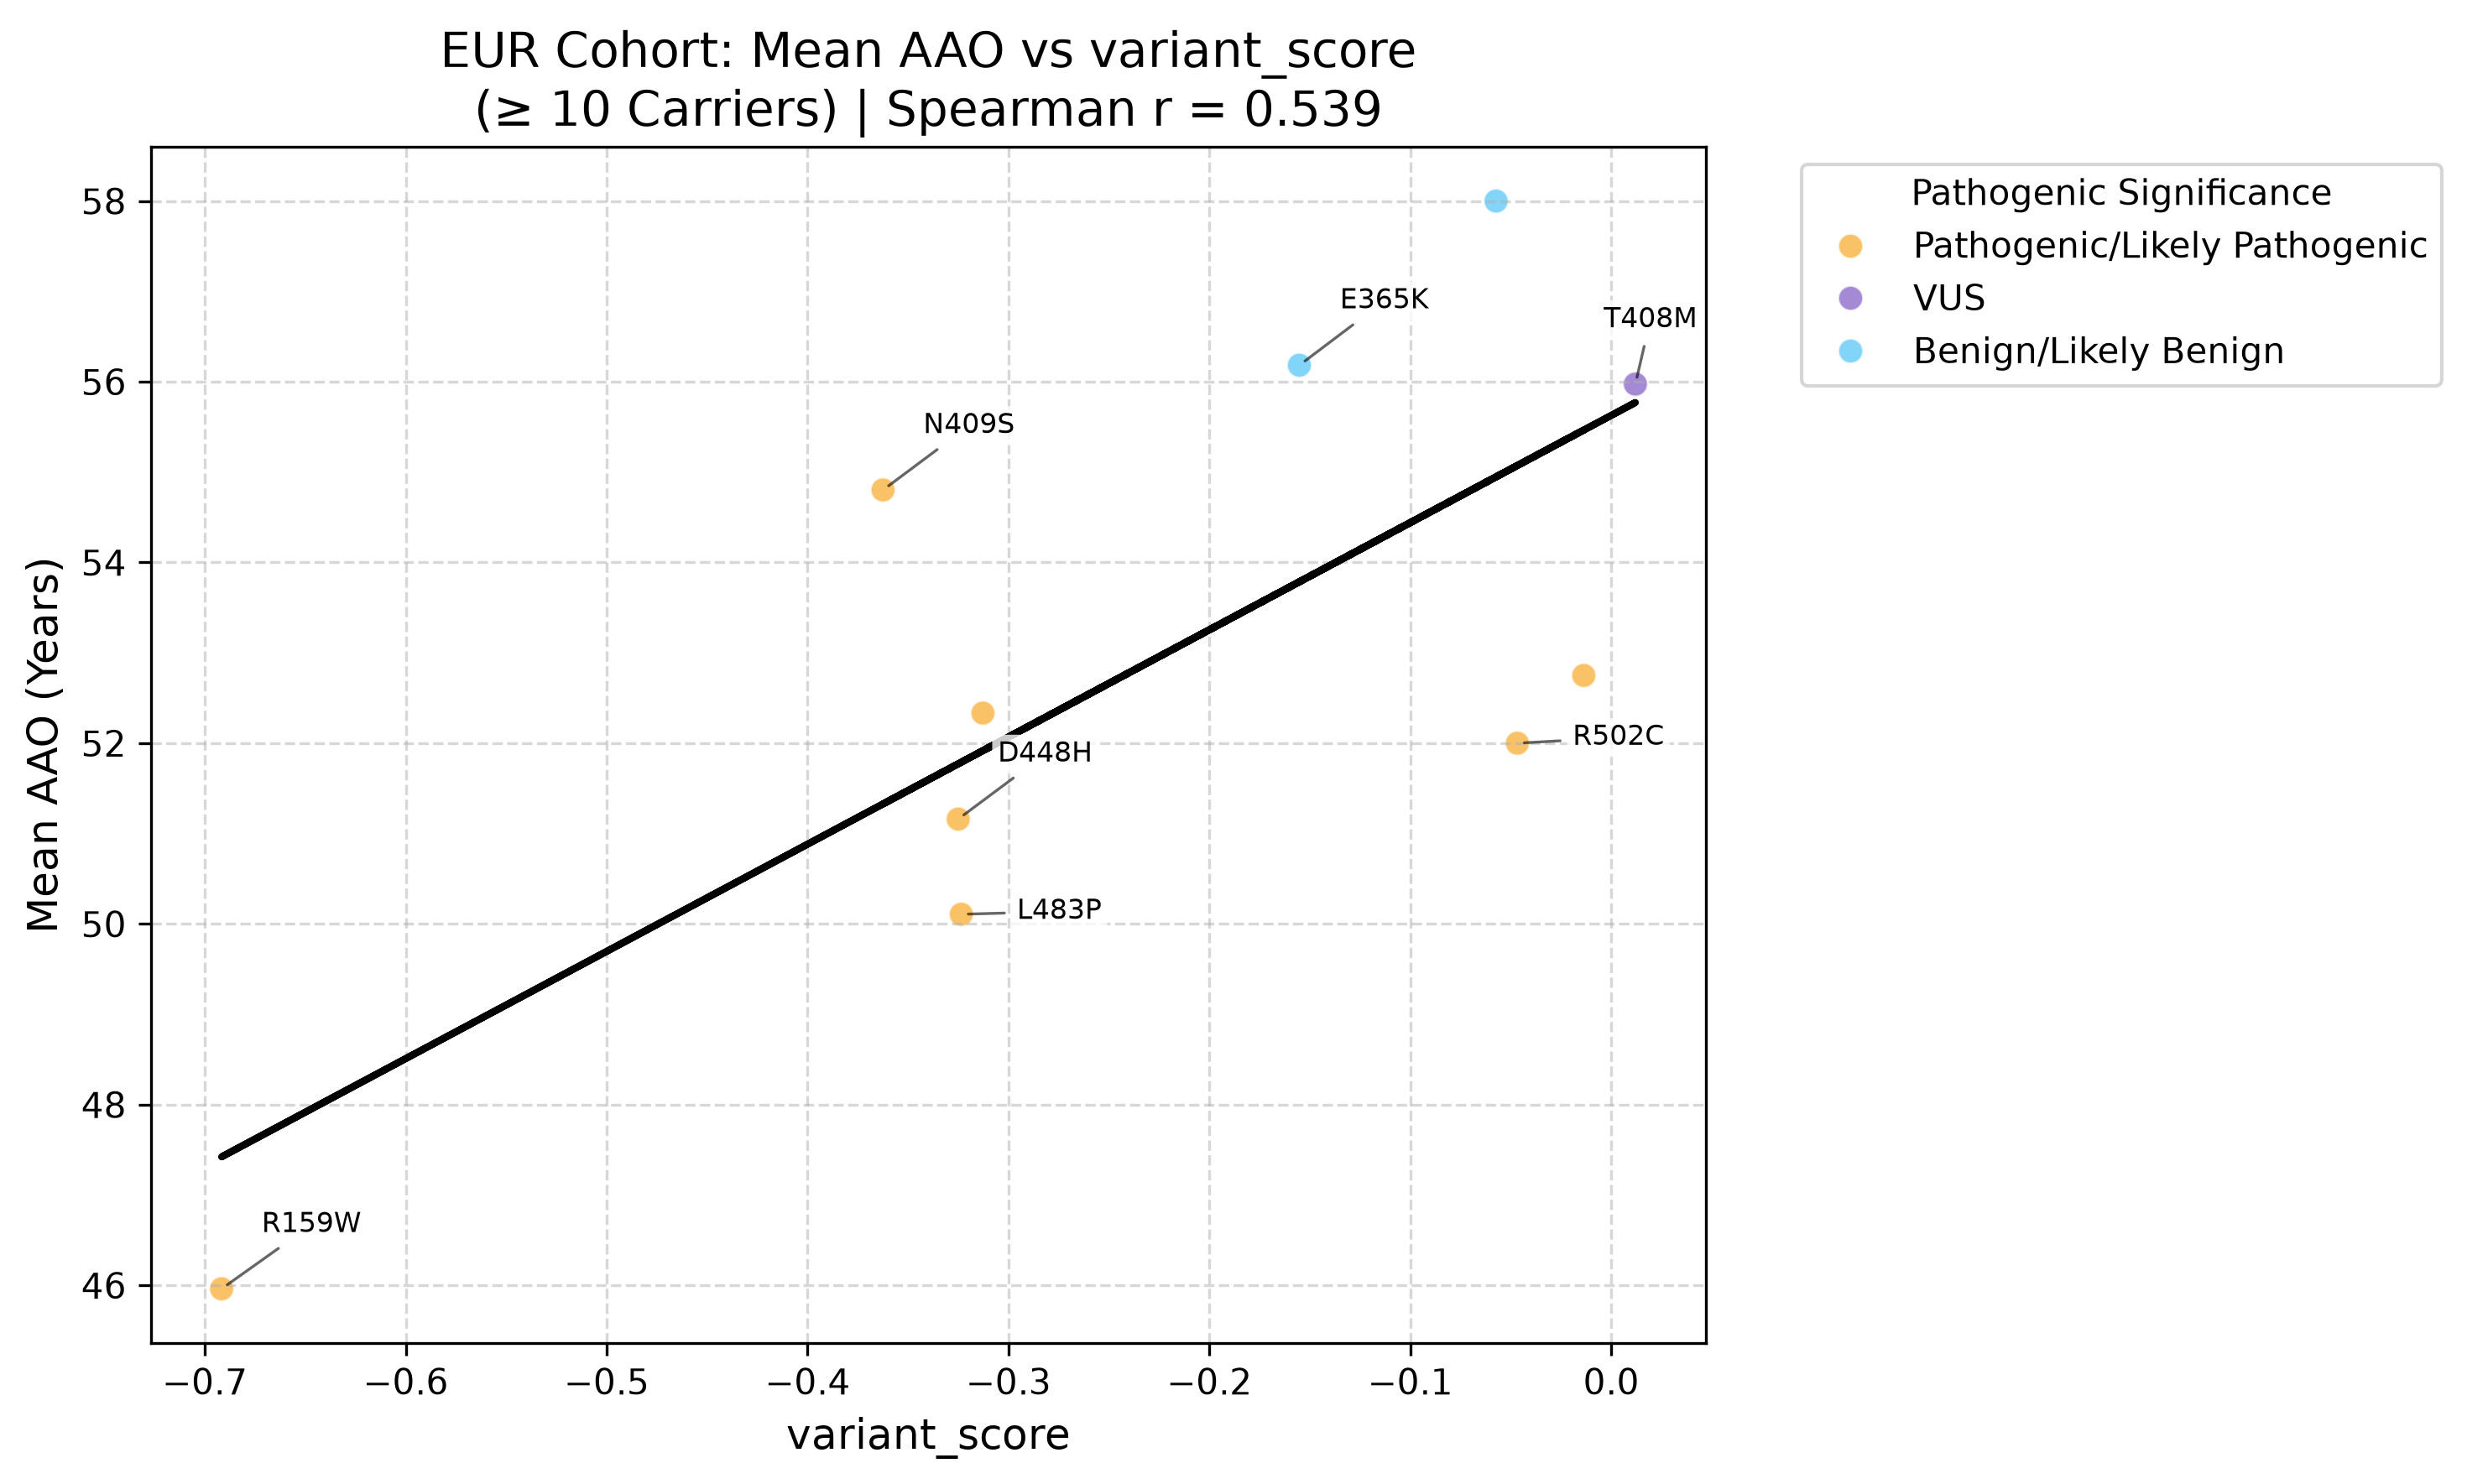

In [14]:
from IPython.display import Image, display
import os

# Define the path to the newly saved PNG
png_path = os.path.expanduser("~/Desktop/MAVE/AAO_standard/AAO_PathColored_EUR_Only/EUR_Only_mean_val_vs_score_min_10.png")

# Display it in the notebook
display(Image(filename=png_path))

## MAVE vs OR
    - Standardized coloring
    - Labeled variants
    - MAC filtering

In [6]:
# 1. Load the data
df = pd.read_csv("correlation_sheets/merged_or_scores.csv")
path_df = pd.read_csv("correlation_sheets/pathogenicity_data.csv")

score_col = "variant_score"
target_col = "OR"
path_col = "Combined_MDS_PDBrowser_Classification"
variant_col = "AAchange"  # Column containing the variant names

# List of variants to label
variants_to_label = [
    "R159W", "G241R", "V414L", "V433L", "D448H", "L483P", "R502C", 
    "S310G", "N409S", "W417G", "V437I", "V499L", "E365K", "R83C", 
    "T408M", "N231K", "R324H", "P358L", "V391L", "A495P"
]

# 2. Merge Pathogenicity Classifications
df = pd.merge(df, path_df[['Variant', path_col]], left_on=variant_col, right_on='Variant', how='left')
df[variant_col] = df[variant_col].astype(str).str.strip()
df[path_col] = df[path_col].fillna('Unknown').astype(str).str.strip()
df[path_col] = df[path_col].replace({'nan': 'Unknown', '': 'Unknown', 'None': 'Unknown'})

# 3. EXPLICIT CUSTOM COLOR MAPPING
unique_labels = df[path_col].unique()
custom_palette = {}

for label in unique_labels:
    label_lower = str(label).lower()
    if 'likely pathogenic' in label_lower:
        custom_palette[label] = '#F9A825'
    elif 'pathogenic' in label_lower:
        custom_palette[label] = '#C62828'
    elif 'likely benign' in label_lower:
        custom_palette[label] = '#4FC3F7'
    elif 'benign' in label_lower:
        custom_palette[label] = '#1565C0'
    elif 'vus' in label_lower or 'uncertain' in label_lower:
        custom_palette[label] = '#7E57C2'
    elif 'unknown' in label_lower:
        custom_palette[label] = 'grey'
    else:
        custom_palette[label] = 'grey'      # Fallback

# 4. Clean numeric data
df[score_col] = pd.to_numeric(df[score_col], errors='coerce')
df[target_col] = pd.to_numeric(df[target_col], errors='coerce')
df['PD_AC'] = pd.to_numeric(df['PD_AC'], errors='coerce').fillna(0)
df['CTRL_AC'] = pd.to_numeric(df['CTRL_AC'], errors='coerce').fillna(0)

# Calculate MAC (Minor Allele Count)
df['MAC'] = df['PD_AC'] + df['CTRL_AC']

# Drop rows missing score or OR
df = df.dropna(subset=[score_col, target_col])

# Expand the '~' to the user's home directory
output_dir = os.path.expanduser("~/Desktop/MAVE/OR_test")
os.makedirs(output_dir, exist_ok=True)

# 5. Setup the Side-by-Side Subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
mac_thresholds = [5, 10]

# Loop through the thresholds and the corresponding subplot axes
for ax, mac_min in zip(axes, mac_thresholds):
    # Filter dataset based on MAC threshold
    subset = df[(df['MAC'] >= mac_min) & (df['PD_AC'] > 0) & (df['CTRL_AC'] > 0)]
    
    if len(subset) < 2:
        ax.set_title(f"MAC \u2265 {mac_min}\nNot enough data", fontsize=14)
        continue
        
    corr, p_value = spearmanr(subset[score_col], subset[target_col])
    
    # Plot on the specific axis (ax) using the custom palette
    sns.scatterplot(
        data=subset, x=score_col, y=target_col, hue=path_col,
        palette=custom_palette, alpha=0.7, edgecolor='white', s=50, ax=ax, legend=True
    )
    
    # Add trend line
    m, b = np.polyfit(subset[score_col], subset[target_col], 1)
    ax.plot(subset[score_col], m * subset[score_col] + b, color='black', linewidth=2, linestyle='-')
    
    # --- ADD LABELS FOR SPECIFIC VARIANTS ---
    x_range = subset[score_col].max() - subset[score_col].min()
    y_range = subset[target_col].max() - subset[target_col].min()
    
    # Fallback ranges to avoid division by zero if all points have same value
    x_range = x_range if x_range > 0 else 1
    y_range = y_range if y_range > 0 else 1
    
    texts = []
    for _, row in subset.iterrows():
        variant_name = row[variant_col]
        if variant_name in variants_to_label:
            t = ax.annotate(
                variant_name, 
                xy=(row[score_col], row[target_col]), 
                xytext=(row[score_col] + (x_range * 0.03), row[target_col] + (y_range * 0.03)), 
                fontsize=8, 
                color='black',
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, ec="none"),
                arrowprops=dict(arrowstyle="-", color="black", lw=0.8, alpha=0.6)
            )
            texts.append(t)
            
    # Resolve overlapping labels specifically for this axis
    if texts:
        adjust_text(
            texts,
            ax=ax,
            x=subset[score_col].tolist(),  
            y=subset[target_col].tolist(),
            expand_points=(1.2, 1.2)
        )
    
    # Axis formatting
    ax.set_title(f"OR vs {score_col} (MAC \u2265 {mac_min})\nSpearman r = {corr:.3f}", fontsize=14)
    ax.set_xlabel(score_col, fontsize=12)
    ax.set_ylabel("Odds Ratio (OR)", fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.5)

# Clean up legends (remove from the left plot, place nicely outside the right plot)
axes[0].get_legend().remove()
axes[1].legend(title='Pathogenic Significance', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()

# Save as PDF
plt.savefig(f"{output_dir}/OddsRatio_MAC_Subplots_PathColored_NEW.pdf", format='pdf', bbox_inches='tight')

# Save as PNG 
plt.savefig(f"{output_dir}/OddsRatio_MAC_Subplots_PathColored_NEW.png", format='png', dpi=300, bbox_inches='tight')
plt.close()


print(f"Generated Pathogenicity-colored MAC subplots as PDF in '{output_dir}'")

Generated Pathogenicity-colored MAC subplots as PDF in '/Users/pilaralvarezjerez/Desktop/MAVE/OR_test'


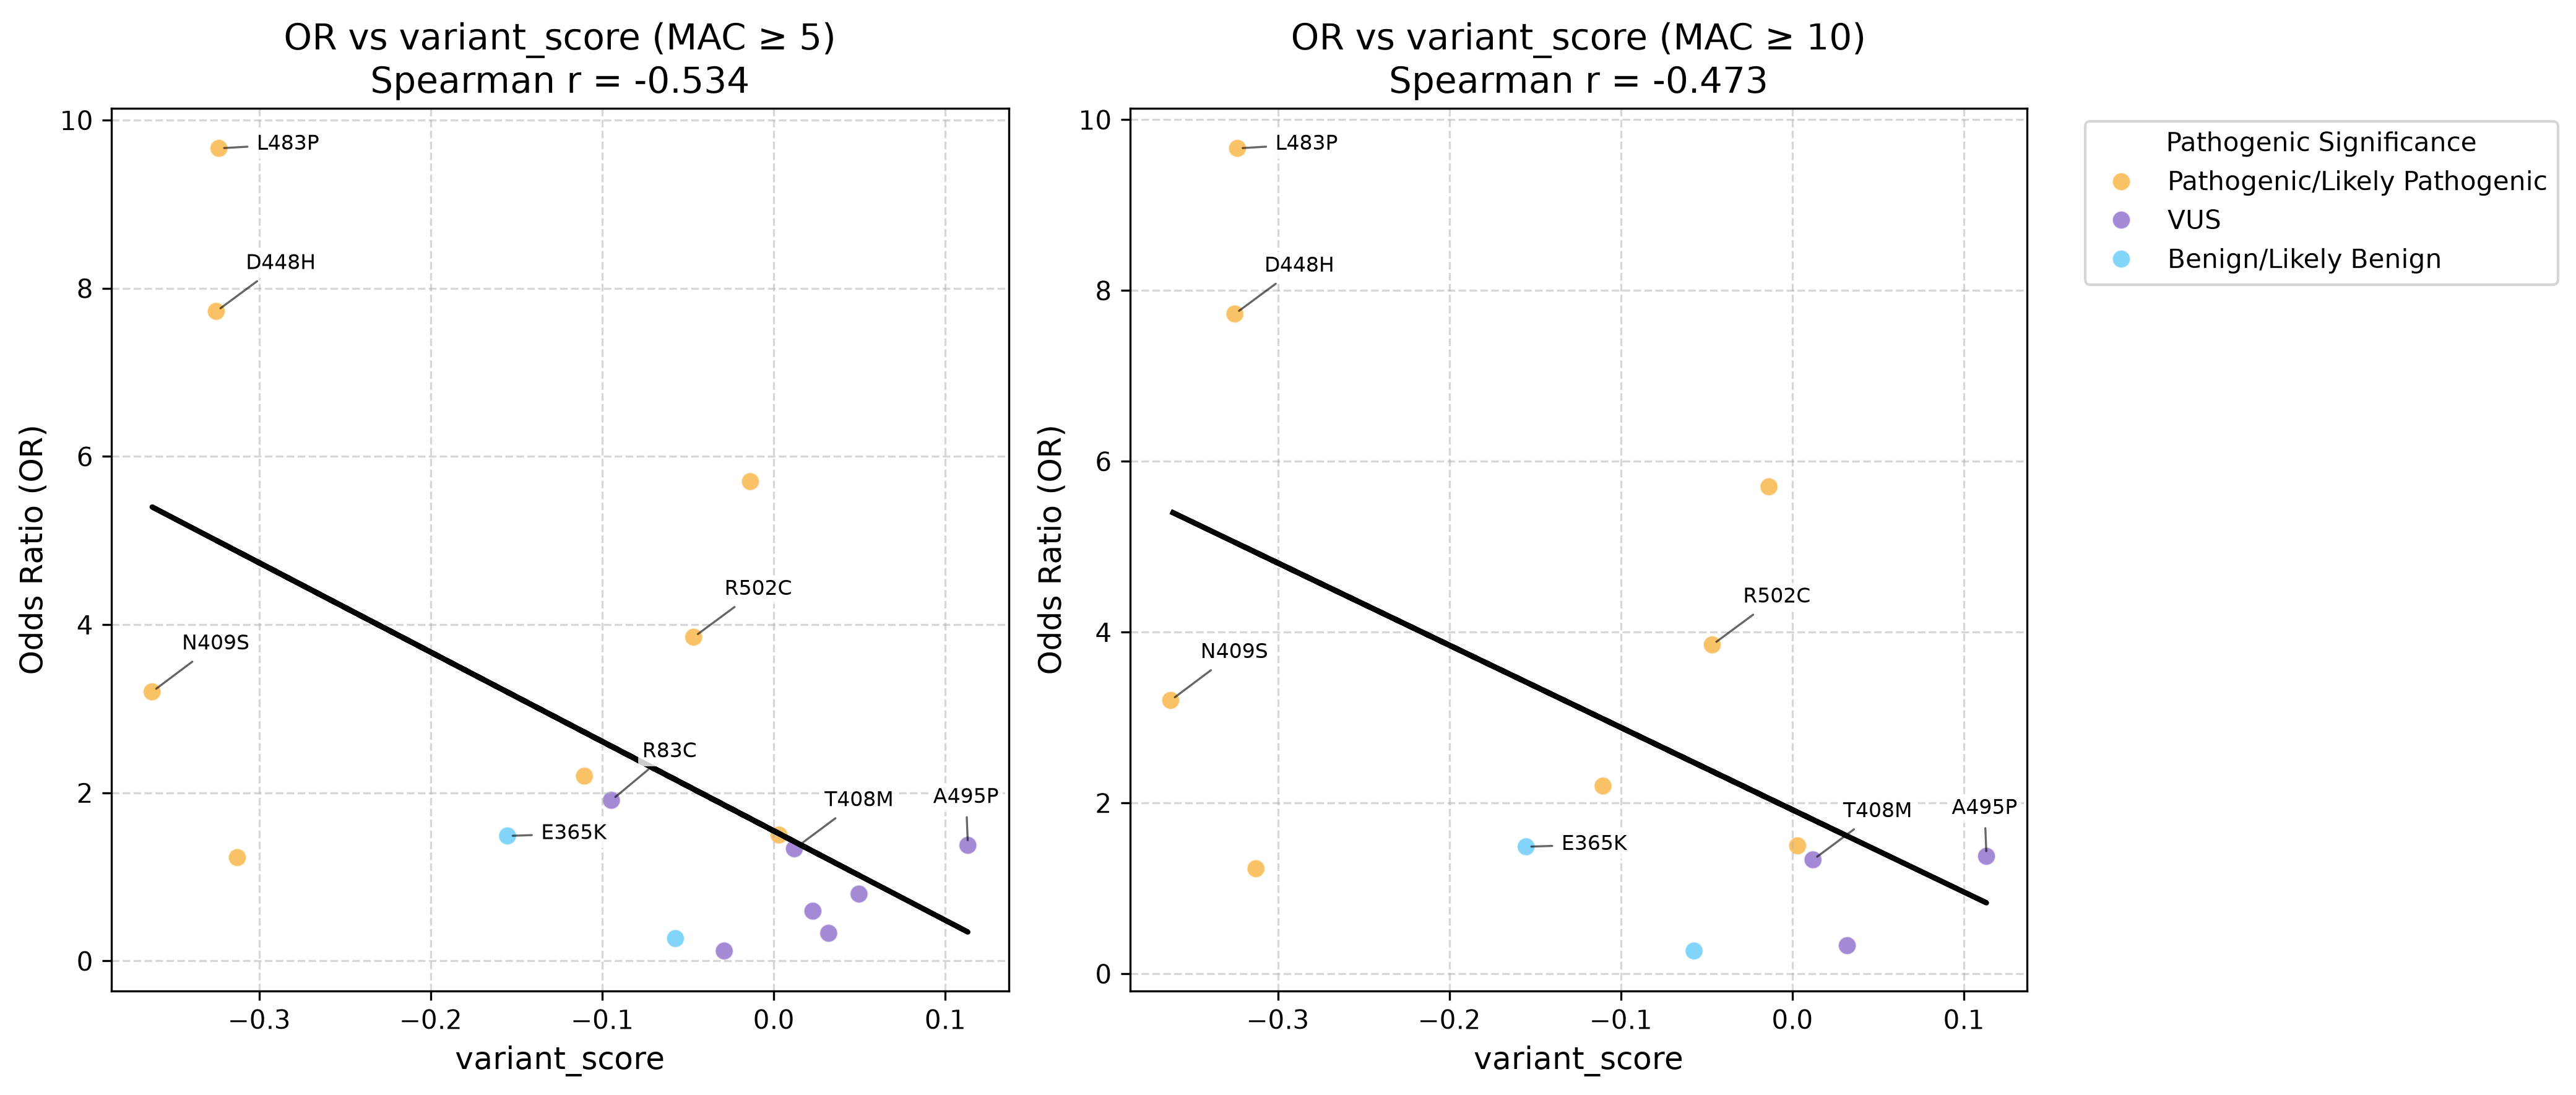

In [7]:
from IPython.display import Image, display
import os

# Define the path to the newly saved PNG
png_path = os.path.expanduser("~/Desktop/MAVE/OR_test/OddsRatio_MAC_Subplots_PathColored_NEW.png")

# Display it in the notebook
display(Image(filename=png_path))